<a href="https://colab.research.google.com/github/profe-lisakov/prpyecto_final_lisakov2026/blob/main/clase28.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [ ]:
datos = np.loadtxt('mareas_valparaiso.csv', delimiter=",", skiprows=4)


x = datos[:, 0]
y = datos[:, 1]
yerr = datos[:, 2]

print(f'Antes de la limpieza el tamano de x es {x.size}')

mascara = y > -100

x = x[mascara]
y = y[mascara]
yerr = yerr[mascara]

print(f'Despues de la limpieza el tamano de x es {x.size}')



Antes de la limpieza el tamano de x es 684
Despues de la limpieza el tamano de x es 675


<ErrorbarContainer object of 3 artists>

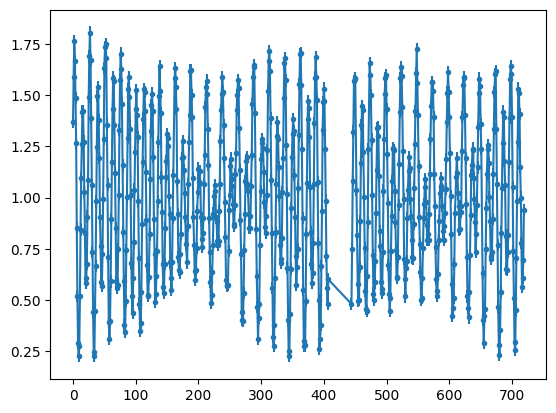

In [ ]:
fig, ax = plt.subplots()
ax.errorbar(x, y, fmt='.-', yerr=yerr)

In [ ]:
# intento 1
# ajuste con la linea recta

def linea(x, a, b):
  return a*x + b


popt, pcov = curve_fit(linea, x, y)
print(f'los parametros optimizados son {popt}')
print(f'la matriz de cov es \n{pcov}')

los parametros optimizados son [-6.07625205e-05  1.02459297e+00]
la matriz de cov es 
[[ 4.68617940e-09 -1.66793970e-06]
 [-1.66793970e-06  8.06440429e-04]]


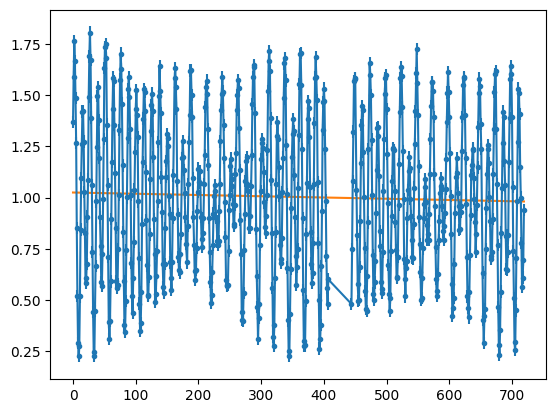

In [ ]:
fig, ax = plt.subplots()
ax.errorbar(x, y, fmt='.-', yerr=yerr)
ax.plot(x, linea(x, *popt))


In [ ]:
# intento 2
# seno-coseno

def seno(x, A, omega, theta, D):
  return A * np.sin(omega * x + theta) + D


popt2, pcov2 = curve_fit(seno, x, y)
print(f'los parametros optimizados son {popt2}')
print(f'la matriz de cov es \n{pcov2}')

los parametros optimizados son [0.00163432 0.99860845 0.34553399 1.00295796]
la matriz de cov es 
[[ 4.26746338e-04  3.69188426e-06 -7.25356261e-04 -2.06377300e-06]
 [ 3.69188426e-06  3.57790725e-03 -1.27175875e+00  3.76694003e-06]
 [-7.25356261e-04 -1.27175875e+00  6.14461184e+02 -1.75149461e-03]
 [-2.06377300e-06  3.76694003e-06 -1.75149461e-03  2.13672029e-04]]


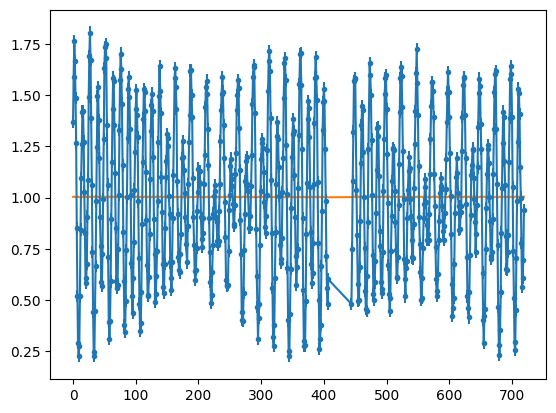

In [ ]:
fig, ax = plt.subplots()
ax.errorbar(x, y, fmt='.-', yerr=yerr)
ax.plot(x, seno(x, *popt2))
